# PacIOOS: mixed layer and water masses at Station ALOHA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ocean-icechunks/2026-ioos-hackathon/blob/main/examples/02-pacioos-aloha-profiles.ipynb)

Two textbook pictures of the open ocean north of Oʻahu, from the
[PacIOOS ROMS Hawaiʻi reanalysis](https://github.com/ocean-icechunks/pacioos/tree/main/stores/roms_hiig_reanalysis)
(3-hourly, 2009–2020, ~4 km, 36 depth levels) as a virtual Icechunk store:

1. the **seasonal mixed layer**, deep in winter and shallow in summer, and
2. the **water masses** in the temperature and salinity profiles.

The point is [Station ALOHA](https://hahana.soest.hawaii.edu/hot/) (22.75 °N, 158 °W), where the
Hawaii Ocean Time-series has sampled monthly since 1988. No credentials needed. Runs on Google
Colab (Python 3.12).

In [ ]:
%pip install -q "icechunk>=2.3" "xarray>=2026.7" "zarr>=3.4" matplotlib

## Open the dataset

The store holds only metadata; every value is read by byte range from the NetCDF files on
Source Cooperative. `chunks=None` keeps it lazy until we select.

In [2]:
import icechunk, xarray as xr, zarr
import numpy as np, matplotlib.pyplot as plt

zarr.config.set({"async.concurrency": 128})   # many small chunks: read lots at once

url = "https://data.source.coop/ocean-icechunks/pacioos/roms_hiig_reanalysis/icechunk"
repo = icechunk.Repository.open(icechunk.http_storage(url))
# Authorize anonymous reads of the NetCDF files, where the data actually live.
auth = {p: icechunk.credentials.HttpAccess for p in repo.config.virtual_chunk_containers}
repo = repo.reopen(authorize_virtual_chunk_access=auth)
ds = xr.open_zarr(repo.readonly_session(tag="v2.0").store, consolidated=False, chunks=None)
ds

<xarray.Dataset> Size: 1TB
Dimensions:  (time: 35040, depth: 36, lat: 195, lon: 295)
Coordinates:
  * time     (time) datetime64[ns] 280kB 2009-01-01 ... 2020-12-28T21:00:00
  * depth    (depth) float32 144B 0.25 1.0 2.0 5.0 ... 4.5e+03 5e+03 5.5e+03
  * lat      (lat) float32 780B 17.02 17.05 17.09 17.13 ... 23.91 23.95 23.98
  * lon      (lon) float32 1kB -163.8 -163.8 -163.8 ... -152.6 -152.6 -152.5
Data variables:
    salt     (time, depth, lat, lon) float32 290GB ...
    mask     (lat, lon) int16 115kB ...
    u        (time, depth, lat, lon) float32 290GB ...
    v        (time, depth, lat, lon) float32 290GB ...
    zeta     (time, lat, lon) float32 8GB ...
    temp     (time, depth, lat, lon) float32 290GB ...
Attributes: (12/54)
    acknowledgement:            The Pacific Islands Ocean Observing System (P...
    comment:                    Model runs produced by Brian Powell (powellb@...
    Conventions:                CF-1.6, ACDD-1.3
    creator_email:              powellb@hawaii.edu
    creator_institution:        University of Hawaii at Manoa
    creator_name:               Brian S. Powell
    ...                         ...
    summary:                    Regional Ocean Modeling System (ROMS) 3-hourl...
    time_coverage_resolution:   PT3H
    title:                      Regional Ocean Modeling System (ROMS): Main H...
    time_coverage_start:        2009-01-01T00:00:00Z
    time_coverage_end:          2020-12-28T21:00:00Z
    source_files:               https://data.source.coop/ocean-icechunks/paci...

## Read profiles at Station ALOHA

One profile per month, 2009–2020: the 15th at 12Z (02:00 in Hawaiʻi, so the afternoon warm
skin is not in it), top 1,500 m, temperature and salinity. Each chunk in this store is one
depth level at one time step, so this is 144 times × 27 levels × 2 variables ≈ 7,800 reads,
about 1.8 GB. That took about 15 s on a JupyterHub in AWS us-west-2.

In [3]:
times = [f"{y}-{m:02d}-15T12" for y in range(2009, 2021) for m in range(1, 13)]

aloha = (ds[["temp", "salt"]]
         .sel(lat=22.75, lon=-158.0, method="nearest")
         .sel(time=times, depth=slice(0, 1500))
         .load())
aloha

<xarray.Dataset> Size: 32kB
Dimensions:  (time: 144, depth: 27)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2009-01-15T12:00:00 ... 2020-12-15T12:...
  * depth    (depth) float32 108B 0.25 1.0 2.0 5.0 ... 1.3e+03 1.4e+03 1.5e+03
    lat      float32 4B 22.76
    lon      float32 4B -158.0
Data variables:
    temp     (time, depth) float32 16kB 23.7 23.7 23.7 ... 3.239 3.043 2.847
    salt     (time, depth) float32 16kB 35.22 35.22 35.22 ... 34.51 34.53 34.55
Attributes: (12/54)
    acknowledgement:            The Pacific Islands Ocean Observing System (P...
    comment:                    Model runs produced by Brian Powell (powellb@...
    Conventions:                CF-1.6, ACDD-1.3
    creator_email:              powellb@hawaii.edu
    creator_institution:        University of Hawaii at Manoa
    creator_name:               Brian S. Powell
    ...                         ...
    summary:                    Regional Ocean Modeling System (ROMS) 3-hourl...
    time_coverage_resolution:   PT3H
    title:                      Regional Ocean Modeling System (ROMS): Main H...
    time_coverage_start:        2009-01-01T00:00:00Z
    time_coverage_end:          2020-12-28T21:00:00Z
    source_files:               https://data.source.coop/ocean-icechunks/paci...

## The seasonal mixed layer

Winter trade winds and surface cooling stir the top of the ocean into a deep, uniform
**mixed layer**; summer heating caps it with a warm, shallow one. For each profile, the mixed
layer depth is where temperature first falls 0.2 °C below its value at 10 m
([de Boyer Montégut et al. 2004](https://doi.org/10.1029/2004JC002378)), interpolated between
model levels. Then average by month.

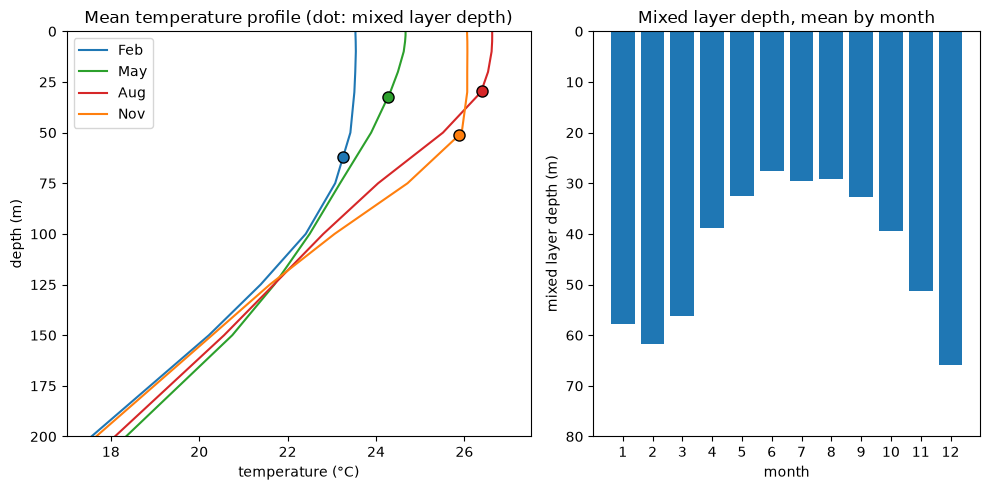

month
1     58.0
2     62.0
3     56.0
4     39.0
5     32.0
6     28.0
7     30.0
8     29.0
9     33.0
10    40.0
11    51.0
12    66.0
Name: temp, dtype: float64

In [4]:
def mixed_layer_depth(temp, depth, dT=0.2, ref=10.0):
    z = np.arange(ref, 500.0, 1.0)              # 1 m steps between model levels
    t = np.interp(z, depth, temp)
    return z[np.argmax(t < t[0] - dT)]          # first depth 0.2 °C colder than at 10 m

mld = xr.apply_ufunc(mixed_layer_depth, aloha.temp, kwargs={"depth": aloha.depth.values},
                     input_core_dims=[["depth"]], vectorize=True)
mld_month = mld.groupby("time.month").mean()
temp_month = aloha.temp.groupby("time.month").mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.2, 1]})
seasons = {2: ("Feb", "tab:blue"), 5: ("May", "tab:green"), 8: ("Aug", "tab:red"), 11: ("Nov", "tab:orange")}
for m, (name, c) in seasons.items():
    prof = temp_month.sel(month=m)
    ax1.plot(prof, prof.depth, color=c, label=name)
    z = float(mld_month.sel(month=m))   # mark the mixed layer depth on each profile
    ax1.plot(np.interp(z, prof.depth, prof), z, "o", color=c, ms=8, mec="k")
ax1.set(ylim=(200, 0), xlim=(17, 27.5), xlabel="temperature (°C)", ylabel="depth (m)",
        title="Mean temperature profile (dot: mixed layer depth)")
ax1.legend()
ax2.bar(mld_month.month, mld_month, color="tab:blue")
ax2.set(ylim=(80, 0), xticks=range(1, 13), xlabel="month", ylabel="mixed layer depth (m)",
        title="Mixed layer depth, mean by month")
plt.tight_layout()
plt.show()
mld_month.round(0).to_series()

The mixed layer is roughly twice as deep in winter (December–March) as in summer
(May–August), the classic seasonal cycle of the subtropical gyre.

## Water masses in the profile

Below the mixed layer, salinity tells you where the water came from:

- a **salinity maximum** near 75–100 m: North Pacific Tropical Water, salty water formed
  under the evaporation-dominated subtropical gyre to the northeast, that sinks and spreads
  south below the surface;
- a **salinity minimum** near 500 m: North Pacific Intermediate Water, fresh water formed far
  to the north in the subpolar Pacific.

In a T–S diagram each water mass is a bend in the curve.

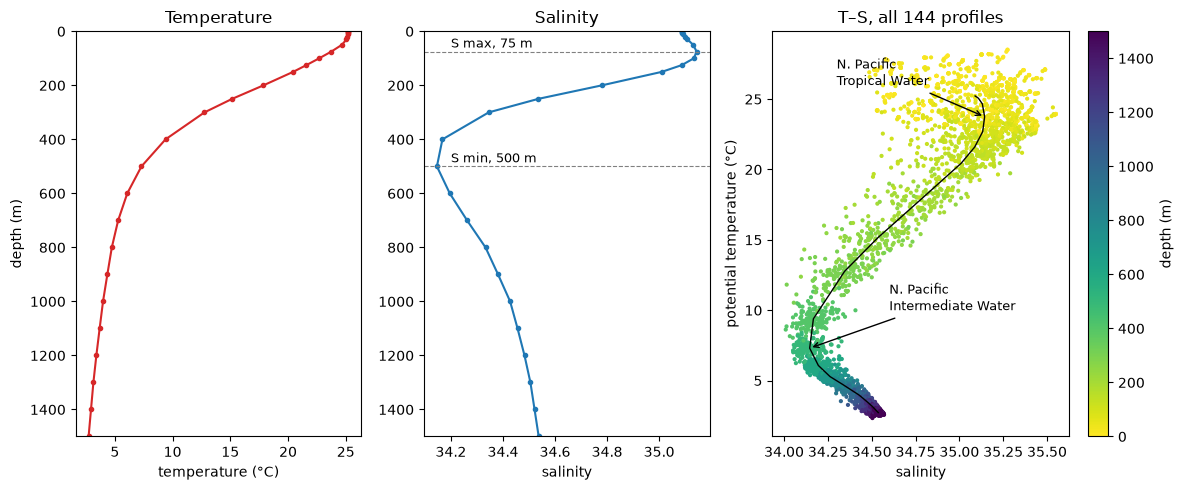

In [5]:
mean = aloha.mean("time")
smax = mean.salt.sel(depth=slice(0, 300)).idxmax().item()
smin = mean.salt.sel(depth=slice(300, 1000)).idxmin().item()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
ax1.plot(mean.temp, mean.depth, "o-", color="tab:red", ms=3)
ax1.set(ylim=(1500, 0), xlabel="temperature (°C)", ylabel="depth (m)", title="Temperature")
ax2.plot(mean.salt, mean.depth, "o-", color="tab:blue", ms=3)
ax2.set(ylim=(1500, 0), xlabel="salinity", title="Salinity")
for z, name in [(smax, "S max"), (smin, "S min")]:
    ax2.axhline(z, color="0.5", lw=0.8, ls="--")
    ax2.text(34.2, z - 15, f"{name}, {z:.0f} m", fontsize=9)

d = aloha.depth.broadcast_like(aloha.temp)
sc = ax3.scatter(aloha.salt, aloha.temp, c=d, s=4, cmap="viridis_r", vmin=0, vmax=1500)
ax3.plot(mean.salt, mean.temp, "k-", lw=1)
for z, name, xy in [(smax, "N. Pacific\nTropical Water", (34.3, 26)),
                    (smin, "N. Pacific\nIntermediate Water", (34.6, 10))]:
    ax3.annotate(name, (mean.salt.sel(depth=z), mean.temp.sel(depth=z)), xytext=xy,
                 fontsize=9, arrowprops=dict(arrowstyle="->"))
ax3.set(xlabel="salinity", ylabel="potential temperature (°C)", title="T–S, all 144 profiles")
fig.colorbar(sc, ax=ax3, label="depth (m)")
plt.tight_layout()
plt.show()

The scatter at the warm end is the seasonal and year-to-year change in the surface water;
below about 300 m the 144 profiles fall in a narrow band, because deep water changes slowly.

This is a data-assimilating model reanalysis, not observations. To check it,
compare with the HOT program's own ALOHA profiles.

**More:** the [store's README](https://github.com/ocean-icechunks/pacioos/tree/main/stores/roms_hiig_reanalysis)
lists the variables and what reads cost.